---
title: "Flow Matching"
author: "Mark Fuge"
date: "November 9 2025"
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

In the previous chapters, we explored how Denoising Score Matching and Diffusion Models can learn to reverse a stochastic (noise-based) process to generate data. These models gradually destroy structure with noise and then learn to painstakingly reverse that process, step by noisy step.

This raises a question: **Can we achieve the same goal without noise?** What if we could learn a deterministic transformation that smoothly 'flows' a simple base distribution (like a Gaussian) into a complex data distribution? 

This is the core idea behind **Flow Matching**. Instead of learning to reverse a noisy, stochastic process, we learn a deterministic vector field of velocities that directly transports probability mass. We saw these ideas earlier in two cases: first with Optimal Transport GANs, where we had to solve a complex and expensive transport matching problem, and then later with (Continuous) Normalizing Flows, which required computing Jacobian determinants in high dimensions. Flow Matching inherits some of these ideas -- notably the idea of learning a vector field to move data points from CNFs and the notion of pairing sets of points from Optimal Transport -- but avoids many of their computational complexities by making certain approximations. In practice, this approach is often simpler to train, faster to sample from, and offers a different but powerful perspective on generative modeling that those we have looked at so far.

## Learning Objectives

By the end of this chapter, you should be able to:

1. Write down the straight line between a base point and a data point and its velocity. State the flow matching loss as a regression.
2. Explain why the learned velocity field is the average of the velocities of the training pairs. Explain why samples then follow curved paths that never cross, even though each training pair moves on a straight line.
3. Generate samples by integrating the learned ODE. Explain what the sampler needs from the base distribution, the direction of time and the number of steps.
4. Compare flow matching with diffusion and with optimal transport. Say what is deterministic, what is learned, and when the learned map is the optimal transport map.
5. Condition a velocity field on a discrete or continuous variable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
import torch.optim as optim
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from gen_models_utilities import (
    device,
    create_ring_gaussians, 
    make_loader, 
    load_eth_z_logo_data,
    make_conditional_loader_onehot,
    make_conditional_loader_radius,
    plot_conditional_samples_discrete,
    plot_conditional_samples_continuous
)

# Use a consistent style
plt.style.use('seaborn-v0_8-muted')
sns.set_context('talk')

# for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

#device = "cpu"
print(f'Using device: {device}')

Using device: cuda


## The Noise-Free Limit

As we saw last chapter, Diffusion models work by reversing a stochastic process. The sampling is noisy and requires many steps because it has to undo the randomness that was added during the forward process. 

Flow matching takes a more direct route. It learns a deterministic vector field $v_\theta(x_t, t)$ that defines the velocity of particles as they move from a base distribution $p_0$ to the target data distribution $p_1$. The generative process becomes the solution to an ordinary differential equation (ODE):

$$ \frac{dx_t}{dt} = v_\theta(x_t, t) $$

Starting with a sample $x_0 \sim p_0$, we can find the corresponding data sample $x_1$ by integrating this equation from $t=0$ to $t=1$. The path is smooth and deterministic. This is similar in concept to what we saw in the earlier chapter on Continuous Normalizing Flows (CNFs). However, we will see below that the two have different training strategies and properties. 

## Interpolating a Path

Like with CNFs, we need to define a velocity field $v_\theta(x_t, t)$ that smoothly transports samples from the base distribution to the data distribution over time. But how should we define the 'correct' velocity field to learn? In CNFs, we derived it from the instantaneous change of variables formula, but that required computing Jacobian determinants which can be expensive and required the velocity field to have certain regularity properties so that the integral could be computed efficiently. Moreover, training the velocity field required estimating an integral over the entire flow path, which can be computationally intensive, and the numerical ODE solver used to compute the integral had to be differentiable to allow backpropagation back to the learned velocity field.

In contrast, Flow Matching uses a simple but brilliant trick. We don't need to simulate a complex forward process (as in Diffusion Models) or estimate some integral of a flow path (as in CNFs). Instead, we just define a synthetic 'path' by simply drawing a straight line between a sample from our base distribution and a sample from our data distribution. This pair of samples is often called a **synthetic coupling pair**.

Let $x_0 \sim p_\text{base}$ (e.g., a standard Gaussian) and $x_1 \sim p_\text{data}$ (e.g., our ring of Gaussians). Given these two sampled points, we define an interpolated point $x_t$ at time $t \in [0, 1]$ as:

$$ x_t = (1 - t) x_0 + t x_1 $$

This gives us a point on the straight line connecting the noise sample to the data sample. The velocity along this path is constant and easy to calculate:

$$ v_t(x_t) = \frac{dx_t}{dt} = x_1 - x_0 $$

This is our **ground truth** velocity. For any interpolated point $x_t$, the target vector is simply the difference vector between the data point and the noise point that created it. This provides a direct, local supervision signal for training our neural network. Another nice benefit of this approach is that it doesn't place any particular restrictions on the base distribution -- it can be Gaussian, uniform, or any other simple distribution from which we can easily sample, since all we need are coupled pairs of points $(x_0, x_1)$ to define our paths. That is, Flow Matching doesn't require any specific form for $p_\text{base}$, unlike models such as Diffusion Models that assume (and in fact rely upon) on Gaussian noise to be the final base distribution.

To understand what this synthetic coupling means, let's visualize these straight-line paths.

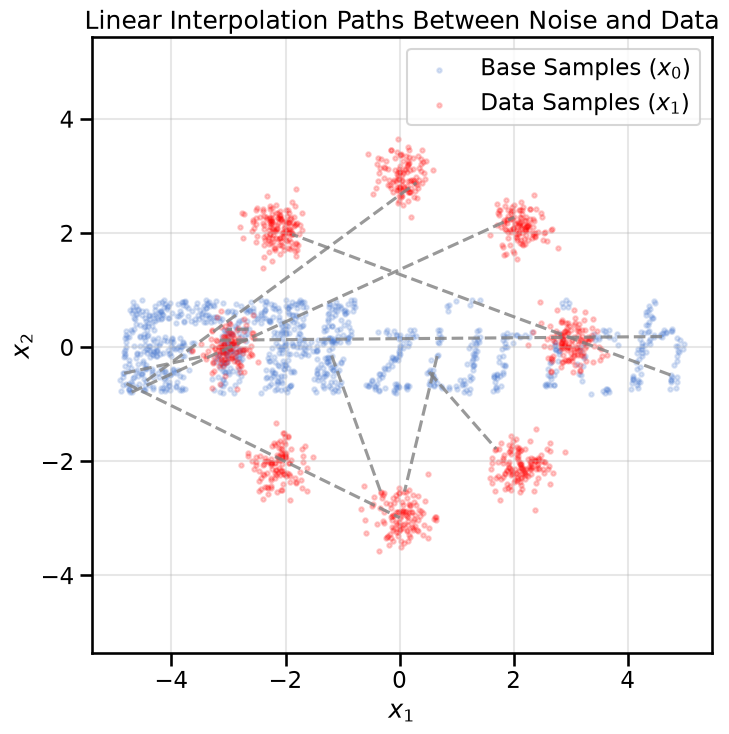

In [2]:

# Load data
data, labels = create_ring_gaussians(n_samples=1000)

BASE_DISTRIBUTION = 'ethz_logo'  # Options: 'gaussian', 'uniform', 'ethz_logo'
# Sample from base distribution
if BASE_DISTRIBUTION == 'gaussian':
    x0_samples = torch.randn(data.shape[0], 2)
elif BASE_DISTRIBUTION == 'uniform':
    x0_samples = torch.rand(data.shape[0], 2)*7.0 - 3.5  # Uniform noise in [-3.5, 3.5]
elif BASE_DISTRIBUTION == 'ethz_logo':
    x0_samples = load_eth_z_logo_data(n_samples=data.shape[0])

# Take a small subset to visualize
n_viz = 10
x0_viz = x0_samples[:n_viz]
x1_viz = torch.from_numpy(data[:n_viz]).float()

plt.figure(figsize=(8, 8))
plt.scatter(x0_samples[:, 0], x0_samples[:, 1], s=10, alpha=0.2, label='Base Samples ($x_0$)')
plt.scatter(data[:, 0], data[:, 1], s=10, alpha=0.2, color='red', label='Data Samples ($x_1$)')

# Draw lines connecting pairs
for i in range(n_viz):
    plt.plot([x0_viz[i, 0], x1_viz[i, 0]], [x0_viz[i, 1], x1_viz[i, 1]], color='gray', linestyle='--', alpha=0.8)

plt.title('Linear Interpolation Paths Between Noise and Data')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Each dashed line represents a simple path from a noise sample to a data sample. Our goal is to train a vector field that will push particles along these kinds of paths.

::: {.callout-note collapse="true"}
### Why pick the pairs of points randomly?

It may first seem odd to randomly pair points from the base and data distributions. Why not try to find the 'best' matching pairs, as we did earlier when we covered Optimal Transport? In that chapter, we saw that by computing the optimal transport map, we could minimize the total cost of moving probability mass, which also seems like it would be useful in flow matching and lead to better paths. One major downside of Optimal Transport is that finding the optimal matching can be computationally expensive, especially in high dimensions or with large datasets. Flow Matching sidesteps this complexity by using completely random pairings as we can see above.

But why should this work? Does a velocity field trained on random pairings still learn to transport mass correctly from the base to the data distribution?

This was the main insight from the [original Flow Matching paper by Lipman et al. (2022)](https://arxiv.org/abs/2210.02747). At a point $x$ and time $t$, the straight lines of many pairs pass through. Each of these pairs has its own velocity $x_1 - x_0$. The velocity field that minimizes the regression loss is the average of these velocities. Lipman et al. showed two things about this averaged field. First, integrating it carries the base distribution onto the data distribution (their Theorem 1). Second, regressing on the velocities of the single pairs finds this averaged field, because the two losses have the same gradient (their Theorem 2). So random pairing guarantees that we end up with the right distribution. It does not guarantee straight paths. Lipman et al. call the straight path from the base to a single data point $x_1$ an optimal transport path. This is their conditional path, given $x_1$. But with random pairs, the flow as a whole is in general not the optimal transport map between the two distributions. Its paths curve, even though every training line is straight.

One dimension is a special case. The paths of a flow cannot cross, so the flow keeps the samples in order. It therefore ends at the monotone map, and in 1D the monotone map is the optimal transport map. So in 1D the end points agree with optimal transport, but the paths still curve.

In two or more dimensions, the flow and the optimal transport map generally differ. Symmetry can still decide part of the answer. Take this chapter's ring with a Gaussian base. Both the flow and the optimal transport map respect the ring's eight-fold symmetry. So both send the $45^\circ$ wedge of the base around each mode's direction to that mode. We checked this with the exact averaged field. For 500 start points, the flow's end points were the same as the optimal transport matching of those points. We also tried less symmetric Gaussian mixtures. There, the flow and optimal transport paired about a fifth of the points differently.

Later work straightens the paths by choosing better pairs. One option is to compute optimal transport within each minibatch ([Tong et al., 2023](https://arxiv.org/abs/2302.00482); [Pooladian et al., 2023](https://arxiv.org/abs/2304.14772)). Another is to train a flow, pair each base sample with the point the flow sends it to, and train again on these new pairs ([rectified flow, Liu et al., 2022](https://arxiv.org/abs/2209.03003)). Still, what made the original paper impressive is that simple random pairing is cheap and works well in practice.

:::

## Training via Velocity Regression

The training objective for Flow Matching is a straightforward regression problem. We want our neural network $v_\theta(x_t, t)$ to predict the true velocity, $x_1 - x_0$, and the loss function is a simple Mean Squared Error:

$$
L(\theta) = \mathbb{E}_{t, x_0, x_1} \left[ \left\| v_\theta((1-t)x_0 + t x_1, t) - (x_1 - x_0) \right\|^2 \right]
$$

This is even simpler than the diffusion model objective. There are no noise schedules ($\alpha_t$, $\beta_t$) to worry about.

### The Training Pipeline

The training process for each step is as follows:

1.  **Sample a Pair:** Pick a noise sample $x_0$ at random from the base distribution and a data sample $x_1$ at random from the training data.
2.  **Sample Time:** Pick a random timestep $t$ uniformly from $[0, 1]$.
3.  **Interpolate:** Compute the point on the path: $x_t = (1-t)x_0 + t x_1$.
4.  **Compute Target Velocity:** The target is simply $v_{target} = x_1 - x_0$.
5.  **Predict Velocity:** Feed $x_t$ and $t$ into the neural network $v_\theta(x_t, t)$ to get the predicted velocity.
6.  **Compute Loss:** Calculate the Mean Squared Error between the network's prediction and the target velocity.
7.  **Update:** Backpropagate and update the network's weights.

Let's implement this. The network architecture will be very similar to the one we used for our diffusion model, as it also needs to be conditioned on time.

Epoch 0, Loss: 9.5181
Epoch 50, Loss: 6.1596
Epoch 100, Loss: 4.2560
Epoch 150, Loss: 4.4698
Epoch 200, Loss: 4.2054
Epoch 250, Loss: 4.5143
Epoch 300, Loss: 4.3328
Epoch 350, Loss: 4.1492
Epoch 400, Loss: 3.9217
Epoch 450, Loss: 4.3062
Epoch 500, Loss: 4.0505
Epoch 550, Loss: 3.7174
Epoch 600, Loss: 3.9791
Epoch 650, Loss: 3.7787
Epoch 700, Loss: 3.7035
Epoch 750, Loss: 4.1699
Epoch 800, Loss: 3.7858
Epoch 850, Loss: 3.9823
Epoch 900, Loss: 3.9018
Epoch 950, Loss: 3.6771
Epoch 1000, Loss: 3.5874
Epoch 1050, Loss: 3.7089
Epoch 1100, Loss: 3.7948
Epoch 1150, Loss: 3.8686
Epoch 1200, Loss: 4.0072
Epoch 1250, Loss: 3.6935
Epoch 1300, Loss: 3.8626
Epoch 1350, Loss: 3.7556
Epoch 1400, Loss: 3.5409
Epoch 1450, Loss: 3.6917
Epoch 1500, Loss: 3.7202
Epoch 1550, Loss: 3.8507
Epoch 1600, Loss: 3.8027
Epoch 1650, Loss: 4.0139
Epoch 1700, Loss: 3.8151
Epoch 1750, Loss: 3.5368
Epoch 1800, Loss: 3.7741
Epoch 1850, Loss: 3.6520
Epoch 1900, Loss: 3.6490
Epoch 1950, Loss: 3.6524
Epoch 2000, Loss: 3.952

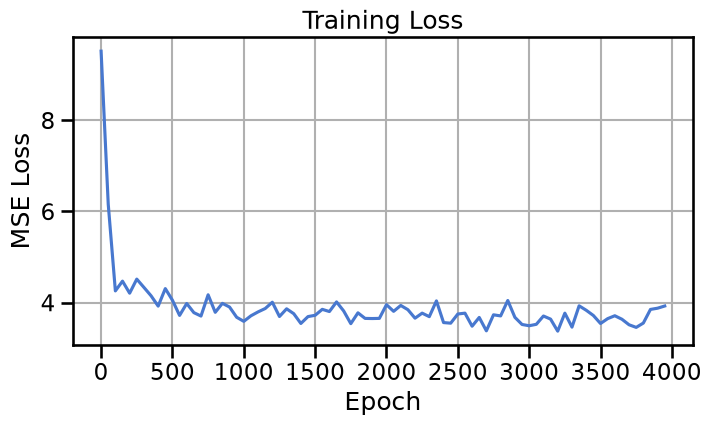

In [3]:
#| code-fold: false
# Time-conditional network to predict velocity
class VelocityField(nn.Module):
    def __init__(self, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        # We can't use an embedding layer for continuous time, so we'll use a small MLP
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2) # Predicts the velocity vector
        )

    def forward(self, x, t):
        # t is expected to be of shape [batch_size, 1]
        t_emb = self.time_mlp(t)
        x_in = torch.cat([x, t_emb], dim=-1)
        return self.net(x_in)

# Training parameters
lr = 1e-3
if BASE_DISTRIBUTION == 'ethz_logo':
    n_epochs = 4000
else:
    n_epochs = 500
batch_size = 1000
loader = make_loader(data, batch_size=batch_size)

# The ETH logo base: load all of its points once, then draw a random subset at every step
if BASE_DISTRIBUTION == 'ethz_logo':
    logo_points = torch.from_numpy(load_eth_z_logo_data(n_samples=np.inf))  # np.inf keeps every point

# Model and optimizer
flow_model = VelocityField().to(device)
optimizer = optim.AdamW(flow_model.parameters(), lr=lr)

# Training loop
losses = []
for epoch in range(n_epochs):
    for (x1_batch,) in loader:
        x1 = x1_batch.to(device)
        
        # 1. Sample noise
        if BASE_DISTRIBUTION == 'gaussian':
            x0 = torch.randn_like(x1)
        elif BASE_DISTRIBUTION == 'uniform':
            x0 = torch.rand_like(x1)*7.0 - 3.5  # Uniform noise in [-3.5, 3.5]
        elif BASE_DISTRIBUTION == 'ethz_logo':
            x0 = logo_points[torch.randint(0, len(logo_points), (x1.shape[0],))]
        x0 = x0.to(device)
        
        # 2. Sample time
        t = torch.rand(x1.shape[0], 1, device=device)
        
        # 3. Interpolate
        xt = (1 - t) * x0 + t * x1
        
        # 4. Compute target velocity
        target_v = x1 - x0
        
        # 5. Predict velocity
        predicted_v = flow_model(xt, t)
        
        # 6. Compute loss
        loss = nn.functional.mse_loss(predicted_v, target_v)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    if epoch % 50 == 0:
        losses.append(loss.item())
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

print("Training complete.")

# Plot the loss curve
plt.figure(figsize=(8, 4))
plt.plot(range(0, n_epochs, 50), losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


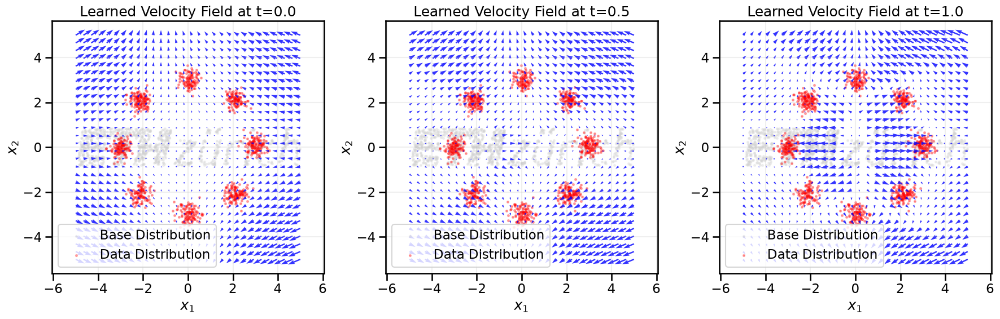

In [4]:
# Visualize the learned velocity field
xx, yy = np.meshgrid(np.linspace(-5, 5, 30), np.linspace(-5, 5, 30))
grid_points = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32, device=device)

# Base distribution samples for the light grey background
if BASE_DISTRIBUTION == 'gaussian':
    base_samples = np.random.randn(1000, 2)
elif BASE_DISTRIBUTION == 'uniform':
    base_samples = np.random.rand(1000, 2)*7.0 - 3.5  # Uniform noise in [-3.5, 3.5]
elif BASE_DISTRIBUTION == 'ethz_logo':
    base_samples = load_eth_z_logo_data(n_samples=1000)

# Get the velocity at each grid point at different times
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
times_to_viz = [0.0, 0.5, 1.0]

for idx, t_val in enumerate(times_to_viz):
    ax = axes[idx]
    
    # Create time tensor
    t_grid = torch.full((grid_points.shape[0], 1), t_val, device=device)
    
    # Get velocity predictions
    flow_model.eval()
    with torch.no_grad():
        velocities = flow_model(grid_points, t_grid).cpu().numpy()
    
    ax.scatter(base_samples[:, 0], base_samples[:, 1], s=5, color='lightgrey', alpha=0.3, label='Base Distribution')
    
    # Plot data samples in red
    ax.scatter(data[:, 0], data[:, 1], s=5, color='red', alpha=0.3, label='Data Distribution')
    
    # Plot velocity field
    ax.quiver(grid_points[:, 0].cpu(), grid_points[:, 1].cpu(), 
              velocities[:, 0], velocities[:, 1], 
              color='blue', width=0.005, alpha=0.8)
    
    ax.set_title(f'Learned Velocity Field at t={t_val:.1f}')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.axis('equal')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.grid(True, alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
def animate_velocity_field(model, grid_points, data, times=None, skip=1):
    """Create an inline animation of the learned velocity field over time.

    model: a time-conditional velocity model taking (x, t) -> v
    grid_points: torch tensor of shape [N, 2] with points where to evaluate the field
    data: numpy array of data samples for background plotting
    times: 1D array-like of time values in [0,1]. If None, uses 101 steps.
    skip: sample every `skip` frames for the animation to speed it up.
    """
    if times is None:
        times = np.linspace(0.0, 1.0, 101)
    times = np.asarray(times)

    model.eval()
    xx = grid_points[:, 0].cpu().numpy()
    yy = grid_points[:, 1].cpu().numpy()

    fig, ax = plt.subplots(figsize=(6, 6))

    def update(i):
        ax.clear()
        t_val = float(times[i])
        t_grid = torch.full((grid_points.shape[0], 1), t_val, device=device)
        with torch.no_grad():
            v = model(grid_points, t_grid).cpu().numpy()

        # Background: data samples in red
        ax.scatter(data[:, 0], data[:, 1], s=5, color='red', alpha=0.3)

        # Quiver plot of velocity field
        ax.quiver(xx, yy, v[:, 0], v[:, 1], color='blue', width=0.005, alpha=0.9)
        ax.set_title(f'Learned Velocity Field — t={t_val:.3f}')
        ax.set_xlim(-5, 5)
        ax.set_ylim(-5, 5)
        ax.set_xlabel('$x_1$')
        ax.set_ylabel('$x_2$')
        ax.set_aspect('equal', adjustable='box')
        ax.grid(True, alpha=0.2)

    frames = range(0, len(times), max(1, skip))
    ani = FuncAnimation(fig, update, frames=frames, repeat=False, interval=80)
    plt.close(fig)
    return HTML(ani.to_jshtml())

# Default call: show a 101-frame animation (sample every 2 frames to speed up)
animate_velocity_field(flow_model, grid_points, data, times=np.linspace(0, 1, 101), skip=2)

## Generating Samples by Solving the ODE

Once the velocity field $v_\theta(x, t)$ is trained, we can generate samples by solving the initial value problem defined by our ODE. We start with a random sample from the base distribution, $x_0 \sim p_\text{base}$, and integrate the velocity field from $t=0$ to $t=1$:

$$
x_1 = x_0 + \int_0^1 v_\theta(x_t, t) dt
$$

In practice, we use a numerical ODE solver to approximate this integral. A simple choice is the **Euler method**, where we take small, discrete steps in time:

$$
x_{t + \Delta t} = x_t + v_\theta(x_t, t) \Delta t
$$

We repeat this process from $t=0$ to $t=1$ to get our final sample. More sophisticated solvers like Runge-Kutta (RK4) can provide more accurate solutions with fewer steps.

Let's implement a simple Euler integrator and use it to generate samples. We will animate the process to see the smooth, deterministic flow from noise to data.

In [6]:
#| code-fold: false
@torch.no_grad()
def generate_with_ode_solver(model, n_samples=500, n_steps=100, initial_noise_scale=1.0):
    """Generate samples by solving the ODE with Euler's method.
        Note here that unlike in CNFs, we don't require the ODE solver to be
        differentiable, because we are only using it for sampling points not training.
    """
    model.eval()
    
    # Start with pure noise
    if BASE_DISTRIBUTION == 'gaussian':
        x = torch.randn(n_samples, 2, device=device) * initial_noise_scale
    elif BASE_DISTRIBUTION == 'uniform':
        x = torch.rand(n_samples, 2, device=device)*7.0 - 3.5
    elif BASE_DISTRIBUTION == 'ethz_logo':
        x = torch.tensor(load_eth_z_logo_data(n_samples=n_samples), dtype=torch.float32, device=device)
    
    # Store trajectory for animation
    trajectory = [x.cpu().numpy()]
    
    dt = 1. / n_steps
    
    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        
        # Predict velocity
        v = model(x, t)
        
        # Euler step
        x = x + v * dt
        
        trajectory.append(x.cpu().numpy())
        
    return x.cpu().numpy(), np.array(trajectory)

# Generate samples and their trajectories
generated_samples_flow, trajectory_flow = generate_with_ode_solver(flow_model, n_samples=1000, n_steps=500)


In [7]:

# Create the animation
fig, ax = plt.subplots(figsize=(8, 8))

def update_flow(frame):
    ax.clear()
    
    # Plot the target distribution in the background
    #sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap="viridis", fill=True, alpha=0.3, ax=ax, levels=15)
    ax.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', alpha=0.5)

    # Plot the current state of the samples
    current_samples = trajectory_flow[frame]
    ax.scatter(current_samples[:, 0], current_samples[:, 1], s=10, color='red', alpha=0.8)
    
    ax.set_title(f"Flow Matching: Step {frame}/{trajectory_flow.shape[0]-1}")
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    #ax.axis('equal')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.grid(True, alpha=0.2)

# Create and display the animation
skip_frames = 10
frames = range(0, trajectory_flow.shape[0], skip_frames)
ani_flow = FuncAnimation(fig, update_flow, frames=frames, 
                         repeat=False, interval=50)
plt.close(fig) # Prevent static plot from showing
HTML(ani_flow.to_jshtml())

The animation shows the smooth, deterministic paths the samples take as they are pushed by the learned velocity field. Unlike the stochastic, zig-zagging paths of the diffusion sampler, these particles flow directly and efficiently toward the target distribution.

## Conditional Generation with Flow Matching

As with diffusion models, Flow Matching can be extended to conditional generation tasks. By conditioning the velocity field on additional information (like class labels or text embeddings), we can guide the flow to generate samples that match specific conditions. For example, if we want to generate images of specific classes, we can modify our velocity network to take an additional input representing the class label. During training, we would sample pairs of points $(x_0, x_1)$ along with their corresponding class labels and train the network to predict the velocity conditioned on these labels. Likewise, during sampling, we would start with a noise sample and integrate the ODE while providing the desired condition to the velocity network at each step. 

Below, we will repeat the conditional examples from the diffusion chapter, this time using Flow Matching instead of Diffusion Models. As before, we will first train on a discrete set of classes (the ring of Gaussians) and note how the learned flow fields change as we modify the conditioning label. Then we will show a continuous conditioning example, where we condition on a continuous variable (the radius) to show how flow matching can condition on continuous variables. Both conditional models start from a standard Gaussian base, $x_0 \sim \mathcal{N}(0, I)$. This holds whatever you set `BASE_DISTRIBUTION` to above.

### Conditional Example A — One-Hot Mode Conditioning

In [8]:
#| code-fold: false
class ConditionalVelocityField(nn.Module):
    """Velocity field conditioned on one-hot encoded mode labels."""

    def __init__(self, n_classes=8, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
        )
        # Concatenate: x (2) + time_emb (time_emb_dim) + one_hot (n_classes)
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim + n_classes, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x, t, c):
        """
        Args:
            x: [batch, 2] - spatial coordinates
            t: [batch, 1] - time
            c: [batch, n_classes] - one-hot encoded class labels
        """
        t_emb = self.time_mlp(t)
        x_in = torch.cat([x, t_emb, c], dim=-1)
        return self.net(x_in)


def train_conditional_flow_onehot(
    data, labels, n_epochs=500, batch_size=128, lr=1e-3, n_classes=8
):
    """Train the conditional velocity field with one-hot conditioning.
    """

    # Create conditional data loader
    cond_loader = make_conditional_loader_onehot(
        data=data, labels=labels, batch_size=batch_size, n_classes=n_classes
    )

    # Model and optimizer
    model = ConditionalVelocityField(n_classes=8).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    # Training loop
    losses = []
    for epoch in range(n_epochs):
        epoch_loss = 0.0
        n_batches = 0
        for x1_batch, labels_batch in cond_loader:
            x1 = x1_batch.to(device)
            c = labels_batch.to(device)

            # Sample noise
            x0 = torch.randn_like(x1)

            # Sample time
            t = torch.rand(x1.shape[0], 1, device=device)

            # Interpolate
            xt = (1 - t) * x0 + t * x1

            # Compute target velocity
            target_v = x1 - x0

            # Predict velocity with conditioning
            predicted_v = model(xt, t, c)

            # Compute loss
            loss = nn.functional.mse_loss(predicted_v, target_v)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            n_batches += 1

        avg_loss = epoch_loss / n_batches
        losses.append(avg_loss)

        if epoch % 50 == 0:
            print(f"Epoch {epoch}, Loss: {avg_loss:.4f}")

    print("Conditional training complete.")

    # Plot the loss curve
    plt.figure(figsize=(8, 4))
    plt.plot(range(n_epochs), losses)
    plt.title("Conditional Flow Matching Training Loss (One-Hot)")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.grid(True)
    plt.show()

    return model


@torch.no_grad()
def sample_conditional_flow(model, condition, n_samples=100, n_steps=100):
    """Generate samples using conditional flow matching.

    Args:
        model: Conditional velocity field model
        condition: [batch, n_classes] one-hot encoded condition
        n_samples: Number of samples to generate
        n_steps: Number of ODE integration steps
    """
    model.eval()

    # Start with pure noise
    x = torch.randn(n_samples, 2, device=device)

    # Expand condition to match batch size
    c = condition.repeat(n_samples, 1)

    dt = 1.0 / n_steps

    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        v = model(x, t, c)
        x = x + v * dt

    return x.cpu().numpy()


def visualize_conditional_samples_onehot(model, n_modes=8, n_samples_per_mode=200):
    """Generate and visualize samples for each mode."""
    # Build samples dict expected by the utility plotting function
    samples_by_label = {}
    for mode_idx in range(n_modes):
        condition = torch.zeros(1, n_modes, device=device)
        condition[0, mode_idx] = 1.0
        samples = sample_conditional_flow(
            model, condition, n_samples=n_samples_per_mode
        )
        samples_by_label[int(mode_idx)] = samples

    # Load reference real data for background and labels
    real_data, real_labels = create_ring_gaussians(n_samples=5000, n_modes=n_modes)

    # Visualize using utilities (expects dict and real data/labels)
    plot_conditional_samples_discrete(
        samples_by_label,
        real_data=real_data,
        real_labels=real_labels,
        title="Conditional Flow Matching: One-Hot Mode Conditioning",
    )

Epoch 0, Loss: 5.5506
Epoch 50, Loss: 0.4717
Conditional training complete.


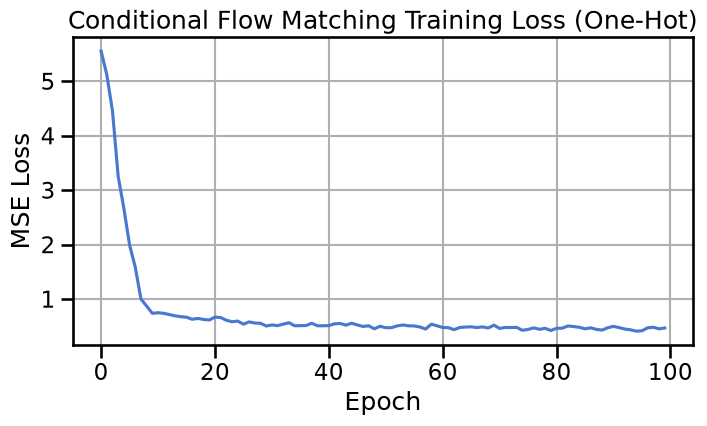

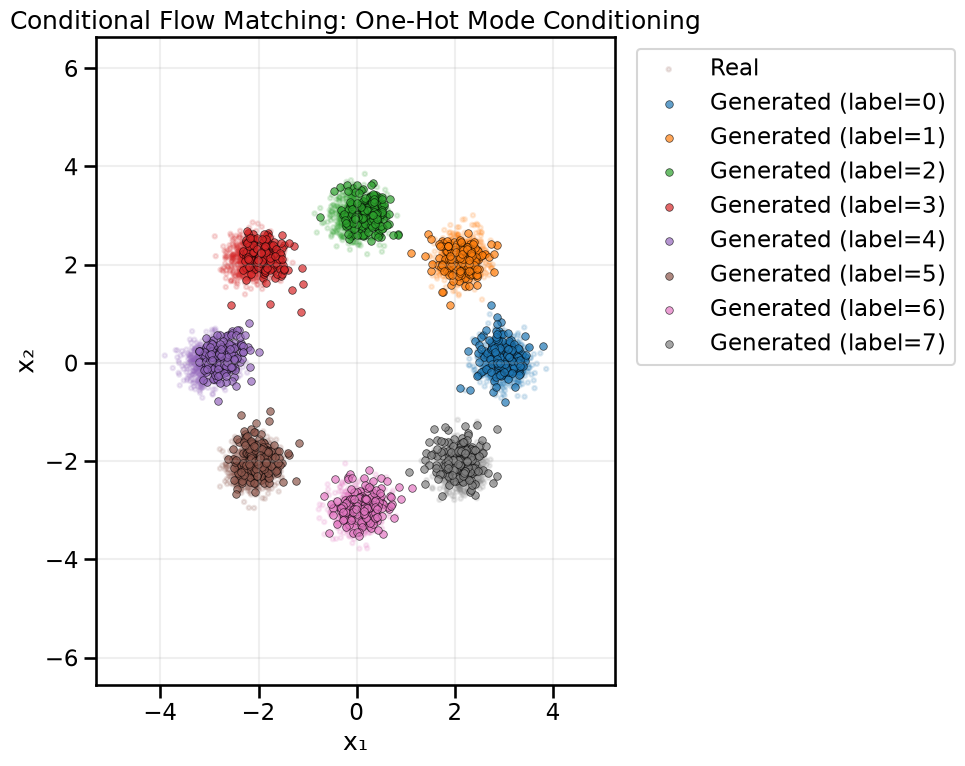

In [9]:
#| code-fold: false
# Train conditional model with one-hot encoding
model_onehot = train_conditional_flow_onehot(data = data, labels=labels,
                                             n_epochs=100, batch_size=128, lr=1e-3)

# Visualize results
visualize_conditional_samples_onehot(
    model_onehot, n_modes=8, n_samples_per_mode=200
)

By looking at the flow fields below, we can see how the conditioning label influences the direction and magnitude of the velocity vectors, guiding samples toward the desired mode in the ring of Gaussians example. The light grey points are samples from the Gaussian base that both models start from.

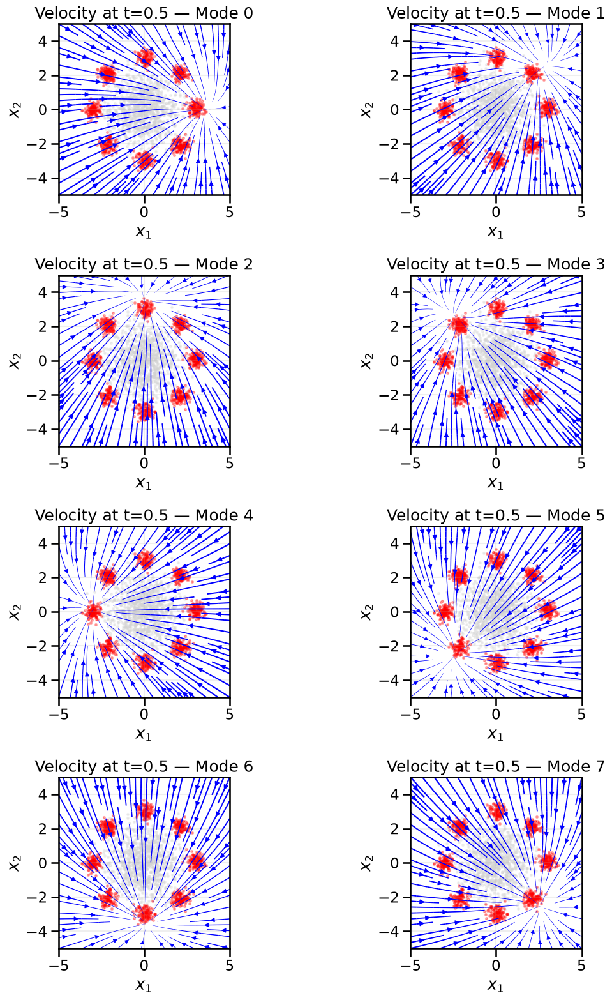

In [10]:
# Check the corresponding learned vector fields for each condition
n_classes = 8
xx_cond, yy_cond = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
grid_points_cond = torch.tensor(np.stack([xx_cond.ravel(), yy_cond.ravel()], axis=1), dtype=torch.float32, device=device)

# Create a 2-column, 4-row figure and plot each mode into a subplot
fig_cond, axes_cond = plt.subplots(4, 2, figsize=(12, 16))
axes_cond = axes_cond.ravel()

# The conditional models start from a standard Gaussian base, so draw that base in the background
base_samples_cond = np.random.randn(1000, 2)

model_onehot.eval()
for mode_idx in range(n_classes):
    ax_cond = axes_cond[mode_idx]
    condition = torch.zeros(1, n_classes, device=device)
    condition[0, mode_idx] = 1.0
    c_grid = condition.repeat(grid_points_cond.shape[0], 1)

    # Get the velocity at each grid point at time t=0.5
    t_grid_cond = torch.full((grid_points_cond.shape[0], 1), 0.5, device=device)
    with torch.no_grad():
        velocities_cond = model_onehot(grid_points_cond, t_grid_cond, c_grid).cpu().numpy()

    # Background: base and data
    ax_cond.scatter(base_samples_cond[:, 0], base_samples_cond[:, 1], s=5, color='lightgrey', alpha=0.3, label='Base Distribution')
    ax_cond.scatter(data[:, 0], data[:, 1], s=5, color='red', alpha=0.3, label='Data Distribution')

    # Streamlines instead of a quiver plot, for a smoother picture
    # Reshape predicted velocities back to the grid shape expected by streamplot
    U = velocities_cond[:, 0].reshape(xx_cond.shape)
    V = velocities_cond[:, 1].reshape(xx_cond.shape)

    # Compute speed for linewidth scaling (avoid div-by-zero)
    speed = np.sqrt(U**2 + V**2)
    max_speed = speed.max() if speed.max() > 0 else 1.0
    linewidths = 1.5 * (speed / max_speed + 0.1)  # add small offset so thin vectors are visible

    # Plot streamlines
    ax_cond.streamplot(
        xx_cond, yy_cond, U, V,
        color='blue',
        linewidth=linewidths,
        density=1.0,
        arrowsize=1.0,
        arrowstyle='-|>',
        maxlength=6.0
    )

    ax_cond.set_title(f'Velocity at t=0.5 — Mode {mode_idx}')
    ax_cond.set_xlabel('$x_1$')
    ax_cond.set_ylabel('$x_2$')
    ax_cond.set_xlim(-5, 5)
    ax_cond.set_ylim(-5, 5)
    ax_cond.set_aspect('equal', adjustable='box')
    ax_cond.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### Conditional Example B — Continuous Radius Conditioning

In [11]:
#| code-fold: false
class ConditionalVelocityFieldRadius(nn.Module):
    """Velocity field conditioned on continuous radius values."""

    def __init__(self, time_emb_dim=16, radius_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.ReLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
        )
        self.radius_mlp = nn.Sequential(
            nn.Linear(1, radius_emb_dim),
            nn.ReLU(),
            nn.Linear(radius_emb_dim, radius_emb_dim),
            nn.ReLU(),
            nn.Linear(radius_emb_dim, radius_emb_dim),
        )
        # Concatenate: x (2) + time_emb + radius_emb
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim + radius_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x, t, r):
        """
        Args:
            x: [batch, 2] - spatial coordinates
            t: [batch, 1] - time
            r: [batch, 1] - radius values
        """
        t_emb = self.time_mlp(t)
        r_emb = self.radius_mlp(r)
        x_in = torch.cat([x, t_emb, r_emb], dim=-1)
        return self.net(x_in)


def train_conditional_flow_radius(data, n_epochs=500, batch_size=128, lr=1e-3):
    """Train the conditional velocity field with radius conditioning.
    """
    # if data is None:
    #     data, _ = create_ring_gaussians(n_samples=5000)

    # Create conditional data loader with radius
    radius_loader = make_conditional_loader_radius(data=data, batch_size=batch_size)

    # Model and optimizer
    model = ConditionalVelocityFieldRadius().to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    # Training loop
    losses = []
    for epoch in range(n_epochs):
        epoch_loss = 0.0
        n_batches = 0
        for x1_batch, radius_batch in radius_loader:
            x1 = x1_batch.to(device)
            r = radius_batch.to(device)

            # Sample noise
            x0 = torch.randn_like(x1)

            # Sample time
            t = torch.rand(x1.shape[0], 1, device=device)

            # Interpolate
            xt = (1 - t) * x0 + t * x1

            # Compute target velocity
            target_v = x1 - x0

            # Predict velocity with radius conditioning
            predicted_v = model(xt, t, r)

            # Compute loss
            loss = nn.functional.mse_loss(predicted_v, target_v)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            n_batches += 1

        avg_loss = epoch_loss / n_batches
        losses.append(avg_loss)

        if epoch % 50 == 0:
            print(f"Epoch {epoch}, Loss: {avg_loss:.4f}")

    print("Conditional training with radius complete.")

    # Plot the loss curve
    plt.figure(figsize=(8, 4))
    plt.plot(range(n_epochs), losses)
    plt.title("Conditional Flow Matching Training Loss (Radius)")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.grid(True)
    plt.show()

    return model


@torch.no_grad()
def sample_conditional_flow_radius(model, radius_value, n_samples=100, n_steps=100):
    """Generate samples using conditional flow matching with radius conditioning.

    Args:
        model: Conditional velocity field model
        radius_value: Scalar radius value to condition on
        n_samples: Number of samples to generate
        n_steps: Number of ODE integration steps
    """
    model.eval()

    # Start with pure noise
    x = torch.randn(n_samples, 2, device=device)

    # Create radius condition
    r = torch.full((n_samples, 1), radius_value, device=device)

    dt = 1.0 / n_steps

    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        v = model(x, t, r)
        x = x + v * dt

    return x.cpu().numpy()


def visualize_conditional_samples_radius(
    model, radius_values=None, n_samples_per_radius=200
):
    """Generate and visualize samples at different radius values."""

    if radius_values is None:
        radius_values = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
    samples_by_value = {}
    for radius_val in radius_values:
        samples = sample_conditional_flow_radius(
            model, radius_val, n_samples=n_samples_per_radius
        )
        samples_by_value[float(radius_val)] = samples

    # Load real data for background
    real_data, _ = create_ring_gaussians(n_samples=5000)

    # Visualize
    plot_conditional_samples_continuous(
        samples_by_value,
        real_data=real_data,
        title="Conditional Flow Matching: Continuous Radius Conditioning",
    )


Epoch 0, Loss: 5.6221
Epoch 50, Loss: 3.0327
Epoch 100, Loss: 2.9449
Epoch 150, Loss: 2.6305
Epoch 200, Loss: 2.6307
Epoch 250, Loss: 3.0152
Conditional training with radius complete.


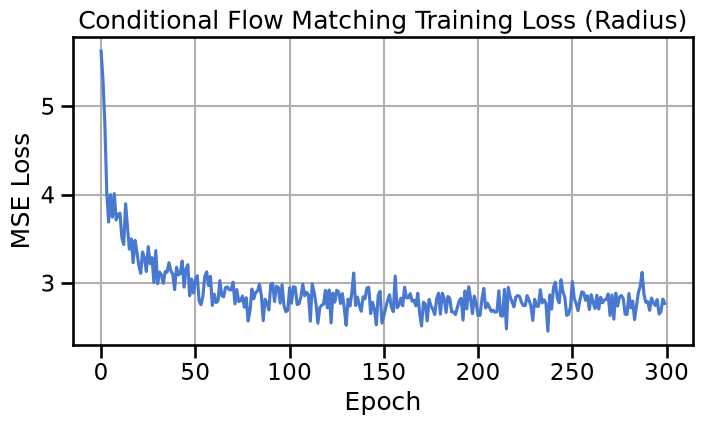

In [12]:
# Train conditional model with radius
model_radius = train_conditional_flow_radius(data=data,n_epochs=300, batch_size=128, lr=1e-3)


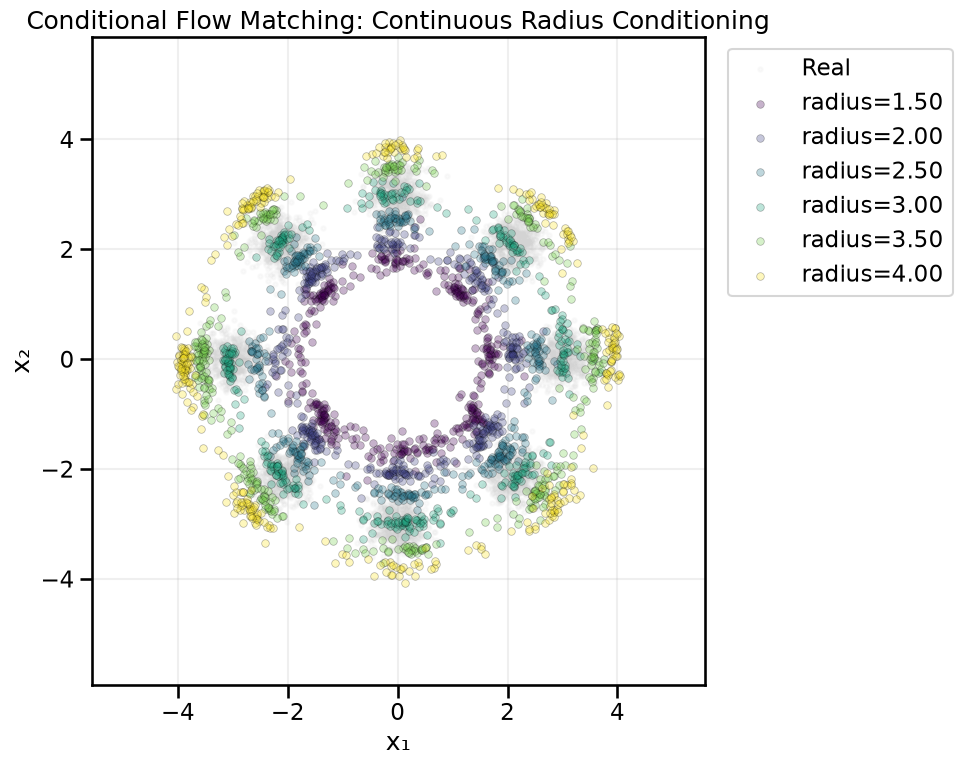

In [13]:

# Visualize results
visualize_conditional_samples_radius(
    model_radius,
    radius_values=[1.5, 2.0, 2.5, 3.0, 3.5, 4.0],
    n_samples_per_radius=400,
)

## Summary and Next Steps

Flow Matching combines some of the best aspects of both Normalizing Flows and Diffusion Models:

| Aspect                  | Diffusion Models        | Normalizing Flows (CNF) | Flow Matching           |
|-------------------------|-------------------------|-------------------------|-------------------------|
| **Dynamics**            | Stochastic (SDE)        | Deterministic (ODE)     | Deterministic (ODE)     |
| **Training**            | Score/Noise Regression  | Max Likelihood (trace)  | Velocity Regression     |
| **Path**                | Random, noisy           | Learned, invertible     | Straight for each training pair, curved when sampling |
| **Sampling**            | Many small noisy steps  | ODE solve (with an adaptive solver in the CNF chapter) | ODE solve. More curved paths need more steps (we used 500 Euler steps). |
| **Stability**           | Very stable             | Can be unstable         | Very stable             |

Flow Matching avoids the expensive trace computation of CNFs and the noise of diffusion sampling. It still has to solve an ODE to generate each sample. The more the learned paths curve, the more steps this takes. It gives us a stable and simple way to learn a generative model.

-   **Flow Matching vs. Diffusion:** Flow Matching learns a deterministic ODE, while diffusion models learn to reverse a stochastic SDE. This makes sampling deterministic, with no noise.
-   **Simple Training:** The model is trained by regressing a time-conditional neural network on the simple velocity vector defined by a straight-line path between noise and data samples.
-   **ODE-based Generation:** Samples are generated by integrating the learned velocity field from $t=0$ to $t=1$ using a numerical ODE solver.

Through this part of the book we have covered a wide variety of generative models, ranging from GANs to VAEs, Normalizing Flows, Diffusion Models, and now Flow Matching. Yet many of these models struggle in high-dimensional settings. A popular and commonly used approach is to combine these Generative Models with reduced or latent dimensional representations, such as those learned by Autoencoders or Variational Autoencoders. In the next chapter we will see how to combine these two threads together to produce "Latent Generative Models", such as Latent Diffusion Models or Latent Flow Models, which leverage the strengths of both generative modeling and representation learning.

## Exercises

These exercises use the ring data and the sampler from the chapter, so run the chapter's cells first. Each title gives a rough time estimate.

In Exercise 1 we move to one dimension. In 1D we can compute the best velocity field for the flow matching loss in closed form, so we do not need a network. The base is the standard normal distribution $p_0(x) = \mathcal{N}(x; 0, 1)$. The data come from the two-mode mixture $p_1(x) = 0.7\,\mathcal{N}(x; -2, 0.6^2) + 0.3\,\mathcal{N}(x; 2, 0.25^2)$. This is the same mixture as in the exercises of the score matching chapter. We draw the pairs independently, as in the chapter. Run the cell below. It makes four panels:

- A: 30 training pairs $(x_0, x_1)$. We draw each pair as its straight line $x_t = (1-t)x_0 + t x_1$ in the $(t, x)$ plane.
- B: the paths of 40 start points under the exact field. We integrate them with 500 Euler steps, as in the chapter, and color them by their final mode.
- C: the exact field $v(x, t)$ at four times.
- D: a histogram of 20,000 samples at $t = 1$, drawn over the target density $p_1(x)$.

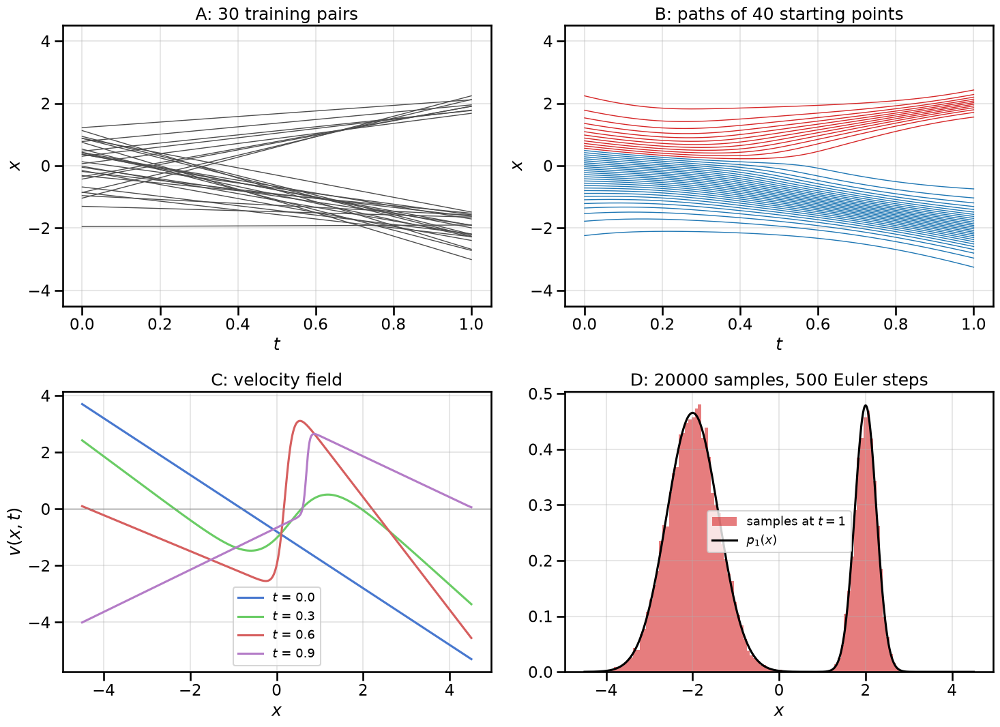

Share of samples in the right mode (x > 0): 0.300 (target 0.30)


In [14]:
#| echo: false
# Figure for Exercise 1: the exact flow matching field for a 1D two-mode mixture with a standard normal base
from scipy.stats import norm

EX_SEED = 42
MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX1_STEPS = 500     # Euler steps, as in the chapter's sampler
EX1_SAMPLES = 20000
EX1_PATHS = 40
EX1_PAIRS = 30


def mix_pdf(x):
    return (MIX_W * np.exp(-0.5 * ((x[:, None] - MIX_MU) / MIX_SD) ** 2) / (MIX_SD * np.sqrt(2 * np.pi))).sum(axis=1)


def sample_mix(n, rng):
    k = rng.choice(2, size=n, p=MIX_W)
    return MIX_MU[k] + MIX_SD[k] * rng.standard_normal(n)


def v_exact_1d(x, t):
    # The minimizer of the flow matching loss: the average of x1 - x0 over the pairs whose line passes through x at time t
    var = (1 - t) ** 2 + t ** 2 * MIX_SD ** 2          # variance of x_t within each mode
    d = x[:, None] - t * MIX_MU                         # offset of x from each mode's mean of x_t
    log_r = np.log(MIX_W) - 0.5 * d ** 2 / var - 0.5 * np.log(var)
    resp = np.exp(log_r - log_r.max(axis=1, keepdims=True))
    resp /= resp.sum(axis=1, keepdims=True)              # which mode the pair through x is likely heading to
    v_mode = MIX_MU + (t * MIX_SD ** 2 - (1 - t)) / var * d  # average of x1 - x0 over the pairs of that mode
    return (resp * v_mode).sum(axis=1)


def euler_1d(x0, n_steps=EX1_STEPS):
    # The chapter's Euler sampler; returns the whole trajectory, shape (n_steps + 1, len(x0))
    x = x0.copy()
    path = [x.copy()]
    for i in range(n_steps):
        x = x + v_exact_1d(x, i / n_steps) / n_steps
        path.append(x.copy())
    return np.array(path)


rng_ex1 = np.random.default_rng(EX_SEED)
pairs_x0 = rng_ex1.standard_normal(EX1_PAIRS)
pairs_x1 = sample_mix(EX1_PAIRS, rng_ex1)
starts_ex1 = norm.ppf((np.arange(EX1_PATHS) + 0.5) / EX1_PATHS)  # starting points spread evenly over the base
paths_ex1 = euler_1d(starts_ex1)
samples_ex1 = euler_1d(rng_ex1.standard_normal(EX1_SAMPLES))[-1]
t_steps = np.linspace(0, 1, EX1_STEPS + 1)
xs_ex1 = np.linspace(-4.5, 4.5, 901)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ax = axes[0, 0]
for a, b in zip(pairs_x0, pairs_x1):
    ax.plot([0, 1], [a, b], color='0.3', linewidth=1)
ax.set_title(f'A: {EX1_PAIRS} training pairs')
ax = axes[0, 1]
for j in range(EX1_PATHS):
    ax.plot(t_steps, paths_ex1[:, j], color='tab:red' if paths_ex1[-1, j] > 0 else 'tab:blue', linewidth=1)
ax.set_title(f'B: paths of {EX1_PATHS} starting points')
for ax in axes[0]:
    ax.set_xlabel('$t$')
    ax.set_ylabel('$x$')
    ax.set_ylim(-4.5, 4.5)
    ax.grid(True, alpha=0.3)
ax = axes[1, 0]
for t_val in [0.0, 0.3, 0.6, 0.9]:
    ax.plot(xs_ex1, v_exact_1d(xs_ex1, t_val), label=f'$t$ = {t_val}')
ax.axhline(0, color='0.5', linewidth=0.8)
ax.set_xlabel('$x$')
ax.set_ylabel('$v(x, t)$')
ax.set_title('C: velocity field')
ax.legend(fontsize=13)
ax.grid(True, alpha=0.3)
ax = axes[1, 1]
ax.hist(samples_ex1, bins=np.linspace(-4.5, 4.5, 121), density=True, color='tab:red', alpha=0.6, label='samples at $t = 1$')
ax.plot(xs_ex1, mix_pdf(xs_ex1), color='k', label='$p_1(x)$')
ax.set_xlabel('$x$')
ax.set_title(f'D: {EX1_SAMPLES} samples, {EX1_STEPS} Euler steps')
ax.legend(loc='center', fontsize=13)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Share of samples in the right mode (x > 0): {np.mean(samples_ex1 > 0):.3f} (target {MIX_W[1]:.2f})')

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~20 min): Straight lines in, curved paths out
Each training pair moves along a straight line at a constant velocity $x_1 - x_0$. The network learns to predict these velocities.

- (a) The training lines in panel A cross each other. The paths in panel B are curved and never cross. Many training lines pass through the same point $(t, x)$. Which velocity does the loss make the network predict at such a point, and why? Why are the paths curved? Why can they not cross?
- (b) In panel C, $v(x, 0)$ is the straight line $-0.8 - x$. It is the same for samples that will end in different modes. What decides which mode a sample ends in? When does the field start to push the two groups apart, and how does it change over time? Why?
- (c) The cell prints the share of samples in the right mode. It is 0.300, which is what we want. In the exercises of the score matching chapter, we ran Langevin sampling with the exact score of the same mixture. With $\alpha = 0.01$, the samples (roughly) stayed in whichever mode they initially started in, which led to about 41% in the right mode. With $\alpha = 0.1$, the narrow right mode emptied, and its samples ended up in the wide left mode. Why does the flow here get the weights right where Langevin sampling did not?
:::

---

Exercise 2 goes back to the chapter's ring. We want to test a sampler without waiting for training. So we use `RingVelocityField`, the exact velocity field that minimizes the chapter's loss for the ring with a standard Gaussian base. A perfectly trained `flow_model` with `BASE_DISTRIBUTION = 'gaussian'` would learn this field. The cell below defines `sample_flow`. It is a copy of the chapter's `generate_with_ode_solver` for the Gaussian base, but one of its lines is wrong.

In [15]:
@torch.no_grad()
def sample_flow(model, n_samples=1000, n_steps=100):
    """Euler sampler for a flow trained with a standard Gaussian base (the chapter's generate_with_ode_solver, Gaussian case)."""
    model.eval()

    # Start with pure noise
    x = torch.rand(n_samples, 2, device=device)

    dt = 1. / n_steps
    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        v = model(x, t)
        x = x + v * dt
    return x.cpu().numpy()

The next cell draws 1000 samples from the exact field twice, once with a correct sampler and once with `sample_flow`. Both use 100 Euler steps and the same seed (so what you are seeing is not because of initialization). The cell then counts the samples in each mode. Mode $k$ sits at $45k$ degrees, measured counterclockwise from the $x_1$ axis.

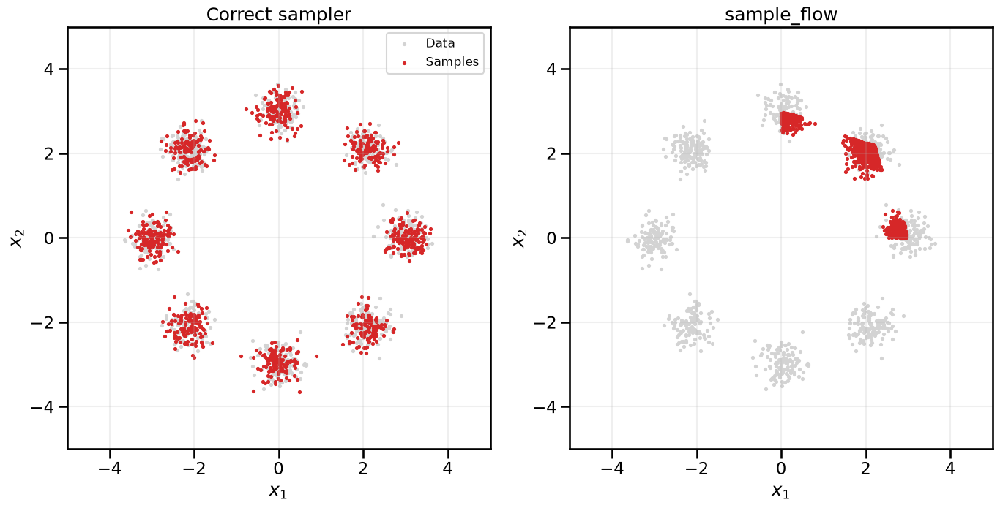

Samples per mode (mode k sits at 45 k degrees):
                   0     1     2     3     4     5     6     7
Correct          140   115   125   128   135   119   125   113
sample_flow      203   575   222     0     0     0     0     0


In [16]:
#| echo: false
# Figure for Exercise 2: the exact ring field, sampled with a correct sampler and with sample_flow above
EX_SEED = 42


class RingVelocityField(nn.Module):
    """Exact minimizer of the flow matching loss for the chapter's ring (8 modes, radius 3, std 0.25),
    with a standard Gaussian base and independent pairs."""

    def __init__(self, n_modes=8, radius=3.0, mode_std=0.25):
        super().__init__()
        angles = torch.arange(n_modes) * 2 * np.pi / n_modes
        self.centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
        self.mode_std = mode_std

    def forward(self, x, t):
        mu = self.centers.to(x.device)
        var = (1 - t) ** 2 + t ** 2 * self.mode_std ** 2       # [n, 1]
        d = x[:, None, :] - t[:, None, :] * mu[None]           # [n, modes, 2]
        resp = torch.softmax(-0.5 * (d ** 2).sum(-1) / var, dim=1)
        v_mode = mu[None] + ((t * self.mode_std ** 2 - (1 - t)) / var)[:, :, None] * d
        return (resp[..., None] * v_mode).sum(1)


@torch.no_grad()
def sample_flow_correct(model, n_samples=1000, n_steps=100):
    model.eval()
    x = torch.randn(n_samples, 2, device=device)
    dt = 1. / n_steps
    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        x = x + model(x, t) * dt
    return x.cpu().numpy()


def count_per_mode(x, n_modes=8):
    # Assign each sample to the nearest mode direction (mode k sits at 45 k degrees)
    k = np.round(np.arctan2(x[:, 1], x[:, 0]) / (2 * np.pi / n_modes)).astype(int) % n_modes
    return np.bincount(k, minlength=n_modes)


ring_field = RingVelocityField()
torch.manual_seed(EX_SEED)
samples_correct = sample_flow_correct(ring_field)
torch.manual_seed(EX_SEED)
samples_buggy = sample_flow(ring_field)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, x, title in [(axes[0], samples_correct, 'Correct sampler'), (axes[1], samples_buggy, 'sample_flow')]:
    ax.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', label='Data')
    ax.scatter(x[:, 0], x[:, 1], s=5, color='tab:red', label='Samples')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

print('Samples per mode (mode k sits at 45 k degrees):')
print(f"{'':14s}" + ''.join(f'{k:>6d}' for k in range(8)))
for name, x in [('Correct', samples_correct), ('sample_flow', samples_buggy)]:
    print(f'{name:14s}' + ''.join(f'{c:6d}' for c in count_per_mode(x)))

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~15 min): Find the bug in the sampler
The velocity field is exact. So any difference between the two panels comes from the wrong line in `sample_flow`.

- (a) Which line is wrong? Why does it send every sample to just three modes?
- (b) Mode 1, the middle of the three, gets close to 60% of the samples. Why that mode, and why approximately that amount?
- (c) The samples that reach a mode fill only a small patch of it. Why?
:::

---

Exercise 3 compares the exact field from Exercise 2 with the exact field of a conditional model. The chapter's one-hot model learns a field that also takes the label $c$ of a mode. For each label, it trains only on pairs whose data point $x_1$ comes from that mode. Suppose we give a perfectly trained model the label of mode 1. It would then learn the exact field for a single Gaussian target at mode 1, with the same standard Gaussian base. Mode 1 sits at radius 3 and 45 degrees and has standard deviation 0.25. Run the cell below. It draws both fields at $t = 0$ as arrows over the data (gray). It also shows the paths of 12 start points from the base, integrated with 100 Euler steps.

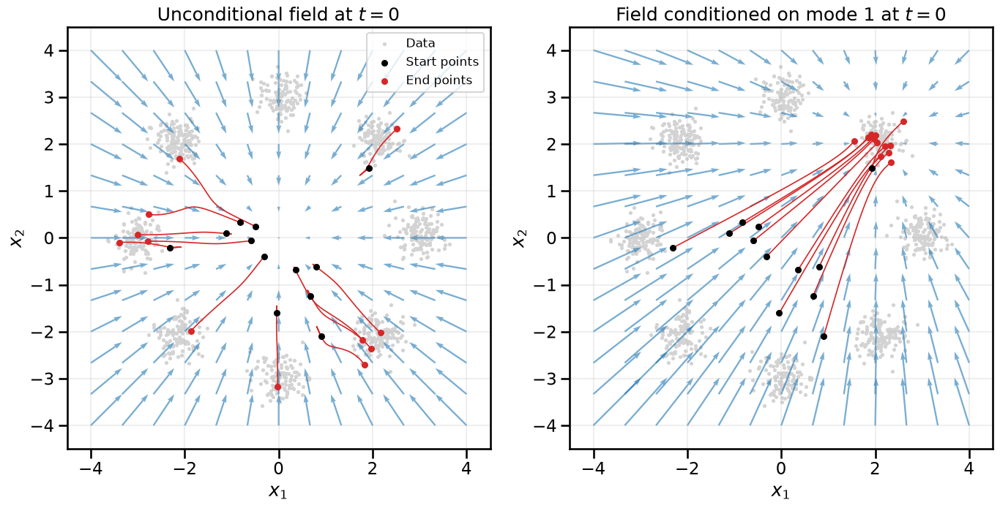

In [17]:
#| echo: false
# Figure for Exercise 3: the exact unconditional ring field and the exact field conditioned on one mode, at t = 0
EX_SEED = 42
EX3_MODE = 1          # the mode the conditional field is conditioned on
EX3_PATHS = 12        # number of start points whose paths are drawn
EX3_STEPS = 100       # Euler steps, as in Exercise 2


class OneModeVelocityField(RingVelocityField):
    """Exact field for the ring conditioned on one mode: the target is a single Gaussian at that mode's center."""

    def __init__(self, mode, **kwargs):
        super().__init__(**kwargs)
        self.centers = self.centers[mode:mode + 1]


@torch.no_grad()
def euler_paths(field, x0, n_steps=EX3_STEPS):
    # Euler integration from the start points x0; returns the trajectory, shape (n_steps + 1, n, 2)
    x = x0.clone()
    path = [x.clone()]
    for i in range(n_steps):
        t = torch.full((x.shape[0], 1), i / n_steps)
        x = x + field(x, t) / n_steps
        path.append(x.clone())
    return torch.stack(path).numpy()


uncond_field = RingVelocityField()
cond_field = OneModeVelocityField(EX3_MODE)
torch.manual_seed(EX_SEED)
starts_ex3 = torch.randn(EX3_PATHS, 2)
grid_1d = torch.linspace(-4, 4, 13)
gx, gy = torch.meshgrid(grid_1d, grid_1d, indexing='xy')
grid_ex3 = torch.stack([gx.flatten(), gy.flatten()], dim=1)
t0 = torch.zeros(grid_ex3.shape[0], 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, field, title in [(axes[0], uncond_field, 'Unconditional field at $t = 0$'),
                         (axes[1], cond_field, f'Field conditioned on mode {EX3_MODE} at $t = 0$')]:
    with torch.no_grad():
        v0 = field(grid_ex3, t0).numpy()
    paths = euler_paths(field, starts_ex3)
    ax.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', label='Data')
    ax.quiver(grid_ex3[:, 0], grid_ex3[:, 1], v0[:, 0], v0[:, 1], color='tab:blue', alpha=0.6,
              angles='xy', scale_units='xy', scale=6, width=0.004)
    for j in range(EX3_PATHS):
        ax.plot(paths[:, j, 0], paths[:, j, 1], color='tab:red', linewidth=1.2)
    ax.scatter(paths[0, :, 0], paths[0, :, 1], s=25, color='k', zorder=3, label='Start points')
    ax.scatter(paths[-1, :, 0], paths[-1, :, 1], s=25, color='tab:red', zorder=3, label='End points')
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~10 min): Conditioning changes the average
Both fields are the average of $x_1 - x_0$ over the pairs whose line passes through $x$ at time $t$, as in Exercise 1. They differ only in which pairs go into the average.

- (a) At $t = 0$, every arrow of the unconditional field points at the origin, which is a place with no target data. Why?
- (b) Why does the conditional field point at mode 1 from the start? Which pairs does conditioning remove from the average?
:::